# 回転拡張の前後で、復元誤差と異常検知性能はどう変わったか

対象：Hybrid CNN＋FC型VAE。36度刻みの回転で正常学習画像を209枚から2,090枚へ増やした、既存実験の振り返りです。

- **図①**：100エポック目の学習画像の復元誤差と、保存済みテスト評価のAUROCを比較します。
- **図②**：学習中の復元誤差の推移を比較します。
- 既存ノートブックの**保存済み出力だけ**を読み取ります。再学習や新しい推論は行いません。

**注意：復元誤差は、それぞれ異なる学習データ上の値です。同一の未学習正常画像での復元性能の比較ではありません。AUROC低下の原因も未確定です。**

上から順に「すべて実行」してください。NumPy・Matplotlib・IPythonを使用します。

In [1]:
from pathlib import Path
import json
import re
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager
from IPython.display import display, Markdown

%matplotlib inline

# リポジトリのルート、codeフォルダのどちらから実行しても参照可能。
ROOT = next(
    (p for p in (Path.cwd(), *Path.cwd().parents)
     if (p / 'code' / '260611.ipynb').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('このリポジトリ内を作業ディレクトリにして実行してください。')

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['Yu Gothic', 'Meiryo', 'MS Gothic', 'Noto Sans CJK JP', 'IPAexGothic']:
    if font_name in available_fonts:
        plt.rcParams['font.family'] = font_name
        break
else:
    try:
        import japanize_matplotlib
    except ImportError:
        print('日本語フォントが見つかりません。日本語フォントを導入してください。')

plt.rcParams.update({'font.size': 11, 'axes.unicode_minus': False, 'figure.dpi': 120})
COLORS = ['#526b8e', '#b27b35']
LABELS = ['拡張前\n209枚', '回転拡張後\n2,090枚']

## 1. 保存済みの結果を読み取る

| 内容 | 参照ノートブック |
|---|---|
| 拡張前の学習ログ（Hybridモデルのみ） | `260611.ipynb` |
| 拡張後の学習ログ | `260718拡張データによる学習.ipynb` |
| 拡張前のAUROC（Hybridモデルのみ） | `260709AUROCを用いた比較評価.ipynb` |
| 拡張後のAUROC | `260719新しいモデルによる検証.ipynb` |

ここでいう「復元誤差」は、コードの `mse_loss(..., reduction='sum')` を各エポックで合計し、学習画像数で割った値です。**1画像あたりの画素の二乗誤差の合計**であり、1画素あたりの平均二乗誤差ではありません。入力は128×128のグレースケール画像、画素値は0〜1です。小さいほど入力に近い復元を意味します。

In [2]:
def read_notebook(name):
    path = ROOT / 'code' / name
    if not path.is_file():
        raise FileNotFoundError(path)
    return json.loads(path.read_text(encoding='utf-8'))


def saved_text(cell):
    # 画像などの出力は読み取らず、保存済みの標準出力のみを使用。
    return ''.join(''.join(out.get('text', [])) for out in cell.get('outputs', []))


def training_history(name, model_name):
    notebook = read_notebook(name)
    candidates = [
        cell for cell in notebook['cells']
        if cell['cell_type'] == 'code'
        and re.search(r'MODEL_NAME\s*=\s*[\"\']' + re.escape(model_name) + r'[\"\']',
                      ''.join(cell.get('source', [])))
    ]
    if len(candidates) != 1:
        raise ValueError(f'{name}: 対象モデルの学習セルを一意に特定できません。')
    rows = re.findall(
        r'Epoch\s*\[\s*(\d+)\s*/\s*(\d+)\s*\].*?MSE:\s*([0-9.eE+\-]+)',
        saved_text(candidates[0]),
    )
    if len(rows) != 100 or [int(e) for e, _, _ in rows] != list(range(1, 101)):
        raise ValueError(f'{name}: 1〜100エポックの保存済みログを確認してください。')
    if any(int(total) != 100 for _, total, _ in rows):
        raise ValueError(f'{name}: 想定外のエポック数です。')
    values = np.array([float(value) for _, _, value in rows])
    if not np.all(np.isfinite(values)) or np.any(values < 0):
        raise ValueError(f'{name}: 復元誤差に不正な値があります。')
    return values


def saved_auroc(name):
    notebook = read_notebook(name)
    values = [
        float(value)
        for cell in notebook['cells']
        for value in re.findall(
            r'\[VAE_Hybrid_CNN5_FC\] AUROC:\s*([0-9.]+)', saved_text(cell)
        )
    ]
    if len(values) != 1 or not 0 <= values[0] <= 1:
        raise ValueError(f'{name}: HybridモデルのAUROCを一意に特定できません。')
    return values[0]


before_history = training_history('260611.ipynb', 'Hybrid_CNN5_FC_Annealing_ep100_beta50')
after_history = training_history(
    '260718拡張データによる学習.ipynb', 'Hybrid_CNN5_FC_Annealing_ep100_beta50_Aug'
)
reconstruction = np.array([before_history[-1], after_history[-1]])
auroc = np.array([
    saved_auroc('260709AUROCを用いた比較評価.ipynb'),
    saved_auroc('260719新しいモデルによる検証.ipynb'),
])
reconstruction_change = (reconstruction[1] / reconstruction[0] - 1) * 100
auroc_change = (auroc[1] / auroc[0] - 1) * 100
auroc_delta = auroc[1] - auroc[0]

display(Markdown(
    '| 指標 | 拡張前 | 回転拡張後 | 変化 |\n'
    '|---|---:|---:|---:|\n'
    f'| 学習画像の復元誤差（100エポック目） | {reconstruction[0]:.4f} | {reconstruction[1]:.4f} | {reconstruction_change:+.2f}% |\n'
    f'| テスト画像のAUROC | {auroc[0]:.4f} | {auroc[1]:.4f} | {auroc_delta:+.4f}（相対変化 {auroc_change:+.2f}%） |'
))

| 指標 | 拡張前 | 回転拡張後 | 変化 |
|---|---:|---:|---:|
| 学習画像の復元誤差（100エポック目） | 32.5971 | 30.3597 | -6.86% |
| テスト画像のAUROC | 0.9683 | 0.9460 | -0.0223（相対変化 -2.30%） |

## 2. 図①：復元誤差は減ったが、AUROCは下がった

左は各学習データの復元誤差、右は保存済みテスト評価の異常検知性能です。**評価している対象も尺度も異なる**ため、棒の高さを左右の図の間で比べることはできません。

どちらも縦軸を0から表示し、差は数値と注釈で示します。AUROCは0〜1で表示します。

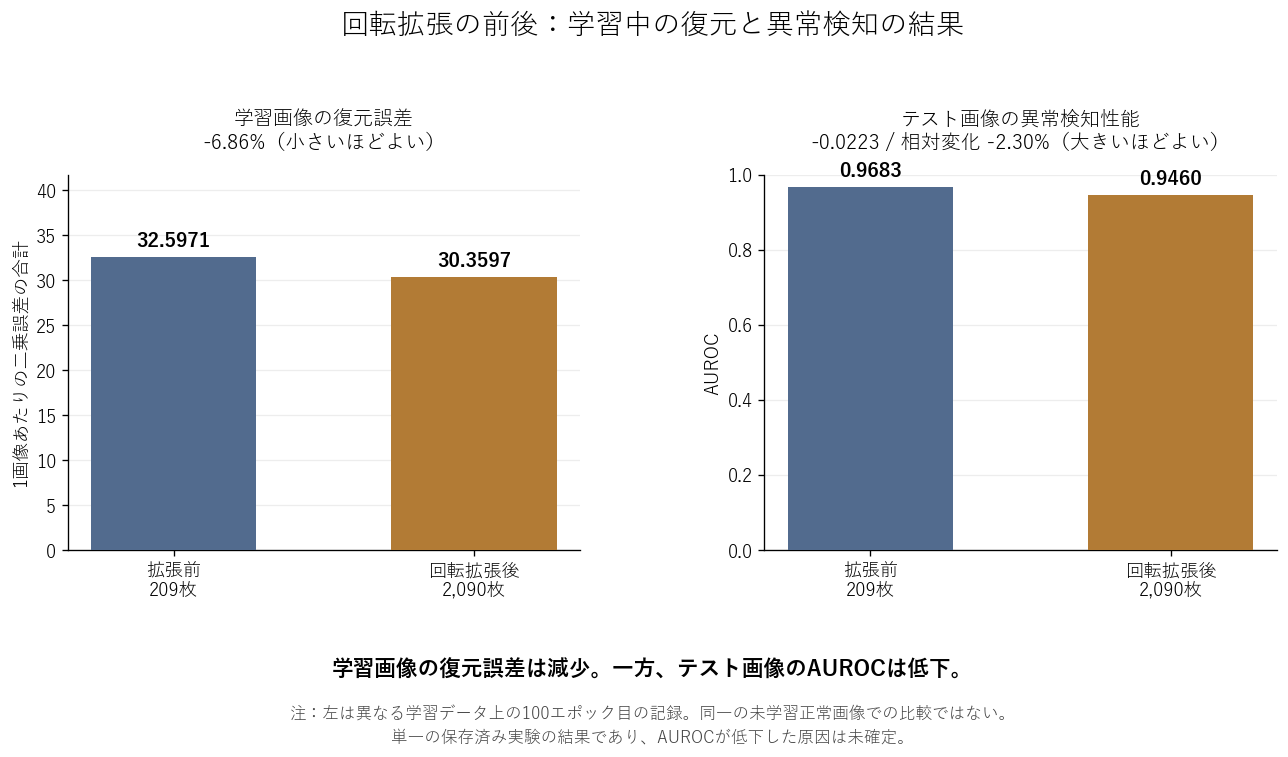

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6.8))
fig.subplots_adjust(top=0.77, bottom=0.31, wspace=0.36)
fig.suptitle('回転拡張の前後：学習中の復元と異常検知の結果', fontsize=17, y=0.97)
x = np.arange(2)

panels = [
    (axes[0], reconstruction, '学習画像の復元誤差', '1画像あたりの二乗誤差の合計',
     max(reconstruction) * 1.28, f'{reconstruction_change:+.2f}%（小さいほどよい）'),
    (axes[1], auroc, 'テスト画像の異常検知性能', 'AUROC',
     1.0, f'{auroc_delta:+.4f} / 相対変化 {auroc_change:+.2f}%（大きいほどよい）'),
]
for ax, values, title, ylabel, ymax, change in panels:
    ax.bar(x, values, color=COLORS, width=0.55, zorder=3)
    ax.set_xticks(x, LABELS)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, ymax)
    ax.set_title(title + '\n' + change, fontsize=12, pad=16)
    ax.grid(axis='y', alpha=0.22, zorder=0)
    ax.spines[['top', 'right']].set_visible(False)
    for i, value in enumerate(values):
        ax.annotate(f'{value:.4f}', (i, value), xytext=(0, 6),
                    textcoords='offset points', ha='center', fontsize=12, weight='bold')

fig.text(0.5, 0.155, '学習画像の復元誤差は減少。一方、テスト画像のAUROCは低下。',
         ha='center', fontsize=13, weight='bold')
fig.text(0.5, 0.075,
         '注：左は異なる学習データ上の100エポック目の記録。同一の未学習正常画像での比較ではない。\n'
         '単一の保存済み実験の結果であり、AUROCが低下した原因は未確定。',
         ha='center', fontsize=10, color='#444444', linespacing=1.6)
plt.show()

## 3. 図②：学習中の復元誤差の推移

左は100エポック全体、右は後半50エポックの拡大図です。左の縦軸は**対数目盛**、右は通常の目盛です。拡張前後とも100エポックですが、拡張後は1エポックの画像数が多く、パラメータ更新の回数も異なります。

学習中にモデルを更新しながら記録した誤差なので、学習完了後に固定したモデルを使って全画像を評価した値とも区別します。

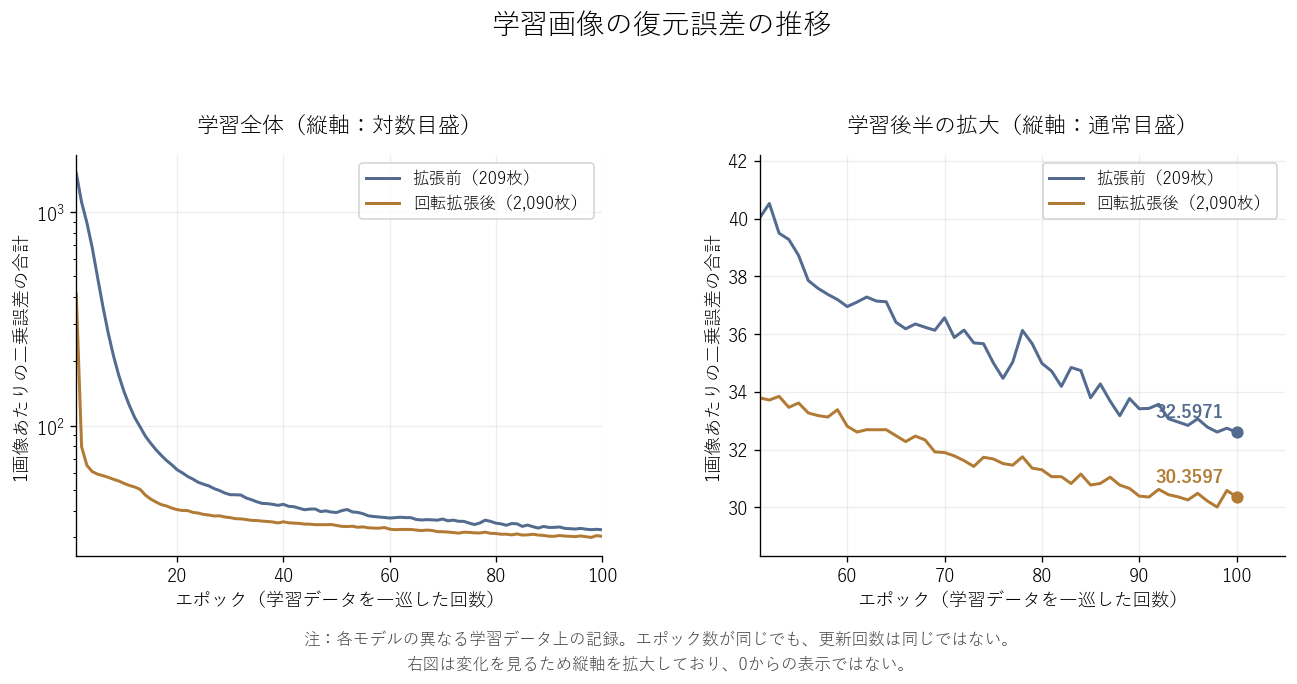

In [4]:
epochs = np.arange(1, 101)
fig, axes = plt.subplots(1, 2, figsize=(13, 6.3))
fig.subplots_adjust(top=0.78, bottom=0.25, wspace=0.30)
fig.suptitle('学習画像の復元誤差の推移', fontsize=17, y=0.97)
for ax in axes:
    for history, color, label in zip(
        [before_history, after_history], COLORS, ['拡張前（209枚）', '回転拡張後（2,090枚）']
    ):
        ax.plot(epochs, history, color=color, label=label, linewidth=1.8)
    ax.set_xlabel('エポック（学習データを一巡した回数）')
    ax.set_ylabel('1画像あたりの二乗誤差の合計')
    ax.grid(alpha=0.22)
    ax.legend(loc='upper right', fontsize=10)
    ax.spines[['top', 'right']].set_visible(False)

axes[0].set_title('学習全体（縦軸：対数目盛）', pad=14)
axes[0].set_yscale('log')
axes[0].set_xlim(1, 100)
axes[1].set_title('学習後半の拡大（縦軸：通常目盛）', pad=14)
axes[1].set_xlim(51, 105)
tail_values = np.concatenate([before_history[50:], after_history[50:]])
padding = max(float(np.ptp(tail_values)) * 0.16, 1.0)
axes[1].set_ylim(max(0, float(tail_values.min()) - padding), float(tail_values.max()) + padding)
for value, color in zip(reconstruction, COLORS):
    axes[1].scatter(100, value, color=color, s=40, zorder=5)
    axes[1].annotate(f'{value:.4f}', (100, value), xytext=(-8, 9),
                     textcoords='offset points', ha='right', color=color, weight='bold')

fig.text(0.5, 0.10,
         '注：各モデルの異なる学習データ上の記録。エポック数が同じでも、更新回数は同じではない。\n'
         '右図は変化を見るため縦軸を拡大しており、0からの表示ではない。',
         ha='center', fontsize=10, color='#444444', linespacing=1.6)
plt.show()

## 4. この図から言えること・まだ言えないこと

**確認できたこと**

- 今回の保存済み実験では、学習画像の復元誤差が減少し、AUROCが低下しました。
- 少なくとも「学習時の復元誤差が小さくなれば、異常検知も必ず良くなる」とはいえません。

**まだ確認できていないこと**

- 同じ未学習正常画像を入力したとき、拡張後のモデルのほうが正確に復元するか。
- 異常画像まで忠実に復元するようになったことが、AUROC低下の原因なのか。
- 回転そのもの、補間、学習更新回数、乱数などの影響を分離した結果。

次に検証するなら、同一の未学習正常画像に対する両モデルの復元画像と誤差を、推論条件を揃えて比較します。異常検知のモデル比較には引き続きAUROCを用い、復元誤差は復元の挙動を調べる補助情報として扱います。